# <font color = "red">**Day 24: Physics-Informed Learning from Atomic-Resolution Microscopy**</font>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_24_11062026/reward_driven_image_analysis.ipynb)

**Challenge Overview**

Atomic-resolution scanning transmission electron microscopy (STEM) provides detailed information about the local structure of crystalline materials. However, extracting physically meaningful properties from microscopy images often requires specialized analysis, atomic-scale measurements, and knowledge of the underlying material structure.

**<font color = "blue">The goal of this challenge is to develop physics-informed algorithms that extract local material properties directly from high-angle annular dark-field (HAADF-STEM) images.</font>**

Participants will work with atomic-resolution images of Sm-doped BiFeO₃ (Sm-BFO) at different compositions (0%, 7%, 10%, 13%, and 20% Sm).

- The primary objective is to reconstruct spatial maps of local polarization-related atomic displacements using image analysis, machine learning, or physics-guided computational methods.

**Participants may use:**

1. HAADF images: Raw atomic-resolution microscopy images.

2. Atomic coordinates (xy_atms): Positions of detected atomic columns.

3. Unit-cell coordinates (xy_COM): Reference positions associated with individual unit cells.

4. Structural parameters: Lattice parameters, unit-cell geometry, and other non-target structural descriptors.

5. Material information: Sm composition and relevant crystallographic knowledge.

Participants may combine these inputs with physical models, computer vision, statistical methods, or machine learning to reconstruct local material properties.

<font color = "red">**Ground Truth and Restrictions**</font>

Reference polarization-related displacement maps **(Pxy)** are provided for verification and evaluation only.

- Participants must not use these reference values as inputs to their algorithms, for model training, or for selecting and optimizing model parameters.

- The reference data may only be used after generating predictions to evaluate the agreement between reconstructed and reference maps.

- Any additional property used as an input must not directly encode or reproduce the reference polarization values.

### load data

In [ ]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
! #gdown --folder "https://drive.google.com/drive/folders/1fXwChjwMT9PH5YtonZoDG3kXVL6mfEQg?usp=sharing"

In [ ]:
#list files
filedir = 'data_small'
# (Surya) also look in my local download folder / Colab
for cand in ['data_small', '/content/data_small',
             r'C:\Users\manda\OneDrive - University of Tennessee\Documents\ChatGPT\CAMM hackthon\drive-download-20261106T191515Z-1-001']:
    if os.path.isdir(cand):
        filedir = cand
        break
[f for f in os.listdir(filedir)]

['Copy of Sm_0_1_HAADF.h5',
 'Copy of Sm_7_3_HAADF.h5',
 'Copy of Sm_20_1_HAADF.h5',
 'Copy of Sm_13_1_HAADF.h5',
 'Copy of Sm_0_1_UCParameterization.h5',
 'Copy of Sm_7_3_UCParameterization.h5',
 'Copy of Sm_10_1_HAADF.h5',
 'Copy of Sm_20_1_UCParameterization.h5',
 'Copy of Sm_10_1_UCParameterization.h5',
 'Copy of Sm_13_1_UCParameterization.h5']

In [ ]:
# Find HAADF images
img_filename = sorted(
    f for f in os.listdir(filedir) if f.endswith("_HAADF.h5")
)

# Match parameterization files
UCparam_filename = [
    f.replace("_HAADF.h5", "_UCParameterization.h5")
    for f in img_filename
]

# Extract Sm composition (%)
composition_tags = [
    int(f.replace("Copy of ", "").split("_")[1])
    for f in img_filename
]

# Load datasets
imgdata = [
    np.asarray(h5py.File(os.path.join(filedir, f), "r")["MainImage"])
    for f in img_filename
]

UCparam = [
    h5py.File(os.path.join(filedir, f), "r")
    for f in UCparam_filename
]

imnum = len(imgdata)

print(f"Loaded {imnum} images and parameterization files")
print("Sm compositions (%):", composition_tags)
print("UC parameters:", list(UCparam[0].keys()))


Loaded 5 images and parameterization files
Sm compositions (%): [0, 10, 13, 20, 7]
UC parameters: ['I1', 'I2', 'I3', 'I4', 'I5', 'NCOM', 'PCOM', 'Pxy', 'Vol', 'a', 'ab', 'abdelta', 'alpha', 'atmindex', 'b', 'index', 'meanuca', 'meanucb', 'nbrUC', 'xy_COM', 'xy_atms']


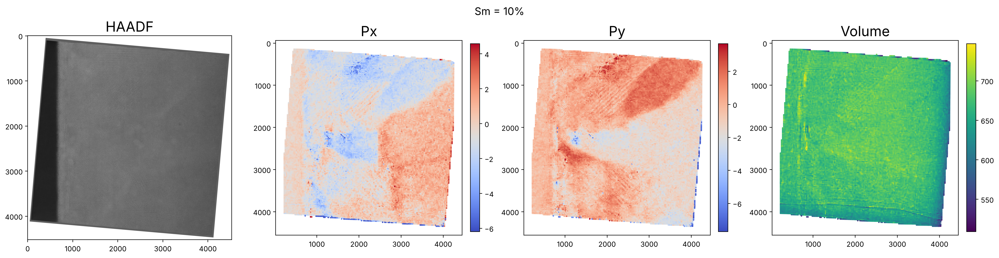

In [ ]:
idx = 1

# Load data
img = np.asarray(imgdata[idx]).squeeze()
pxy = np.asarray(UCparam[idx]["Pxy"]).T
vol = np.asarray(UCparam[idx]["Vol"]).ravel()
xy = np.asarray(UCparam[idx]["xy_COM"]).T

# Extract polarization components
px, py = pxy[:, 0], pxy[:, 1]

# Plot HAADF and unit-cell parameters
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize =20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=5, marker="o", linewidths=0
    )
    ax.invert_yaxis()
    ax.set_title(title, fontsize =20)
    ax.set_aspect("equal")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# for ax in axes:
#     ax.axis("off")

fig.suptitle(f"Sm = {composition_tags[idx]}%", fontsize=15)
plt.tight_layout()
plt.show()


<font color = "red">**Look Closer**</font>

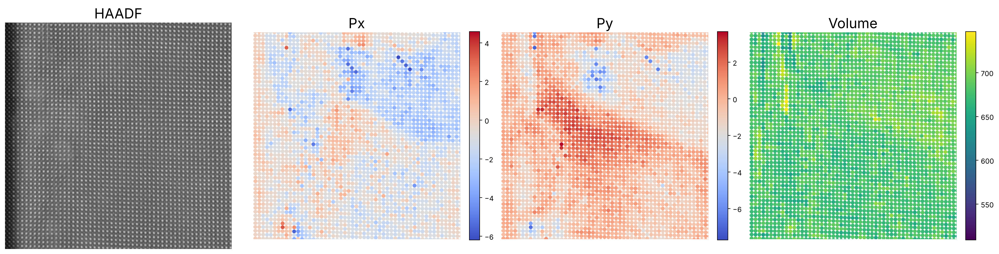

In [ ]:
# Select region (image pixel coordinates)
xlim = (600, 2000)
ylim = (2000, 3400)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize = 20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=30, marker="o", linewidths=0
    )
    ax.set_title(title, fontsize = 20)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(*xlim)
    ax.set_ylim(ylim[1], ylim[0])
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()


<font color = "red">**atom cordinates and center of the mass**</font>

Original shape: (2, 5, 22949)


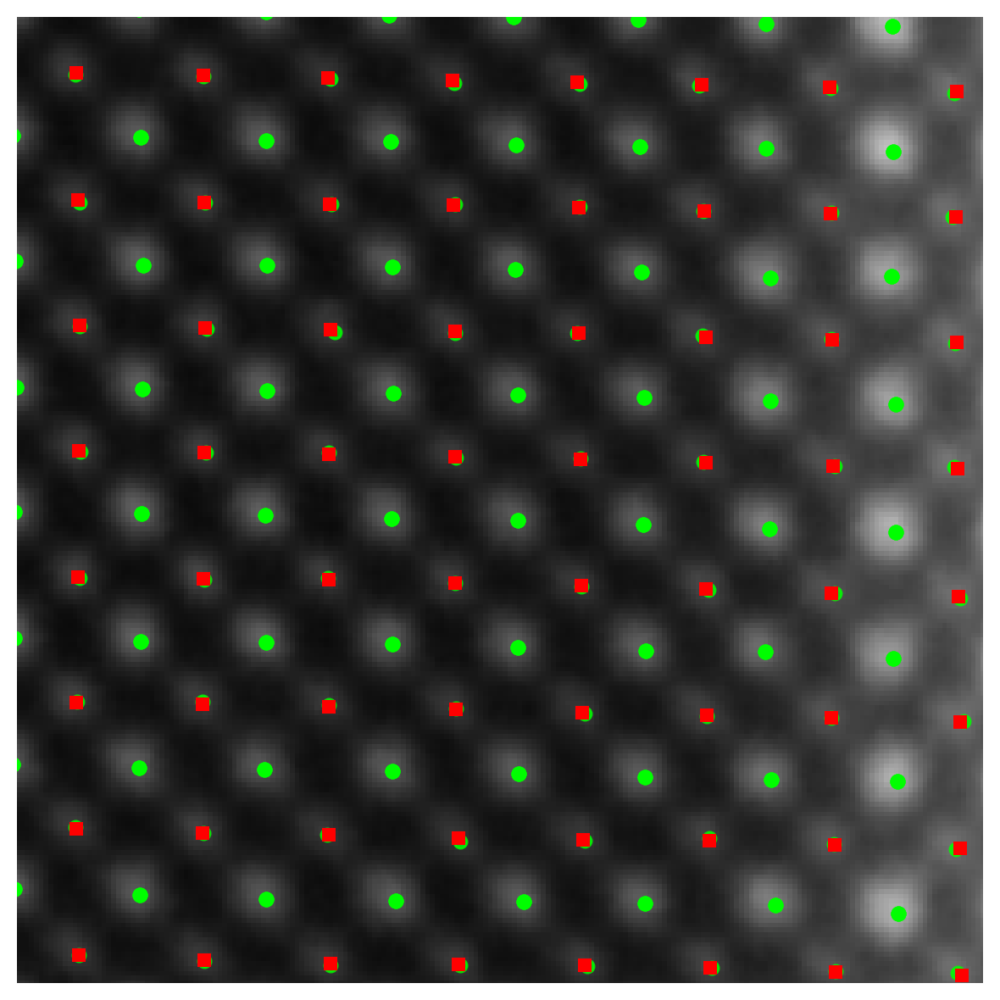

In [ ]:
xlim = (500, 700)
ylim = (500, 700)

xy_atms = np.asarray(UCparam[idx]["xy_atms"]).squeeze()

xy = np.asarray(UCparam[idx]["xy_COM"]).T

print("Original shape:", xy_atms.shape)

# Convert coordinates into (N, 2)
if xy_atms.shape[-1] == 2:
    coords = xy_atms.reshape(-1, 2)
elif xy_atms.shape[0] == 2:
    coords = xy_atms.reshape(2, -1).T
else:
    raise ValueError("Inspect xy_atms structure before plotting")

fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(img, cmap="gray")

ax.scatter(
    coords[:, 1], coords[:, 0],
    s=30, c="lime", alpha=0.8
)

ax.scatter(
    xy[:, 1], xy[:, 0],
    s=30, c="red", marker="s", linewidths=0
)

ax.set_xlim(*xlim)
ax.set_ylim(ylim[1], ylim[0])
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

<font color = "red">**Unit cell**</font>

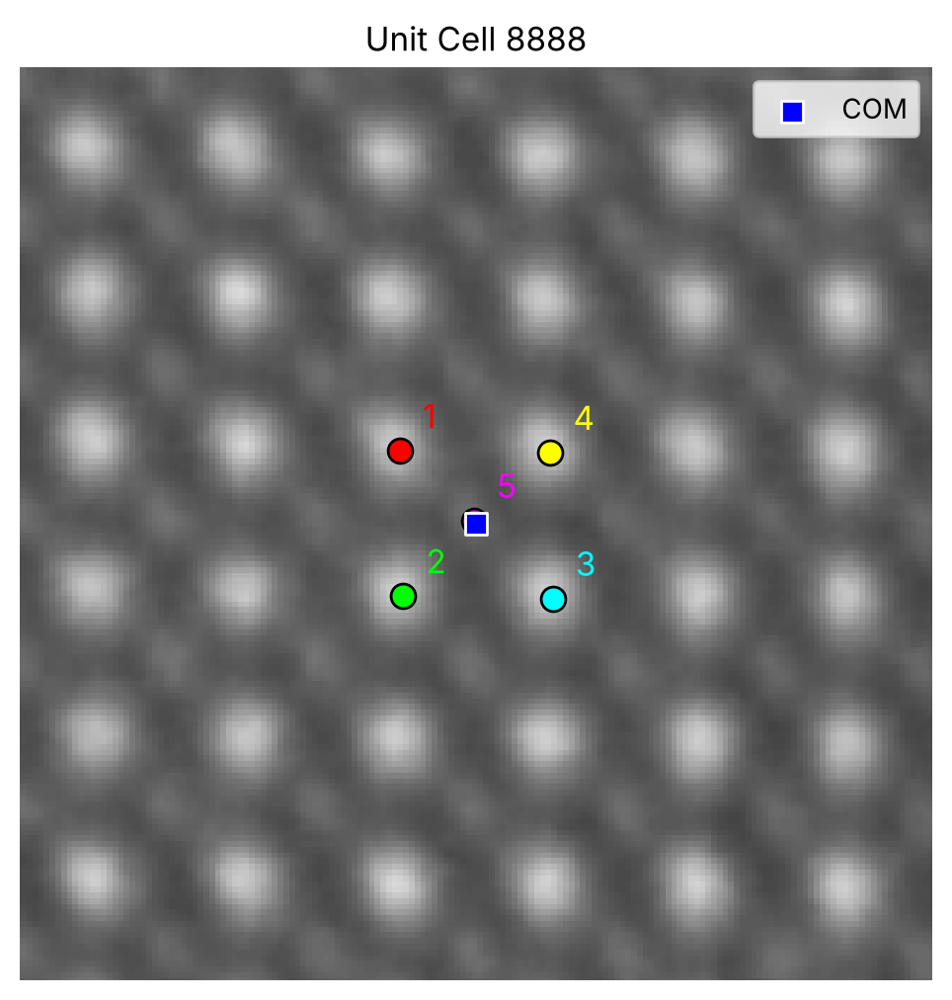

In [ ]:
cell = 8888

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Zoom around the unit cell
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "red">**Polarization**</font>

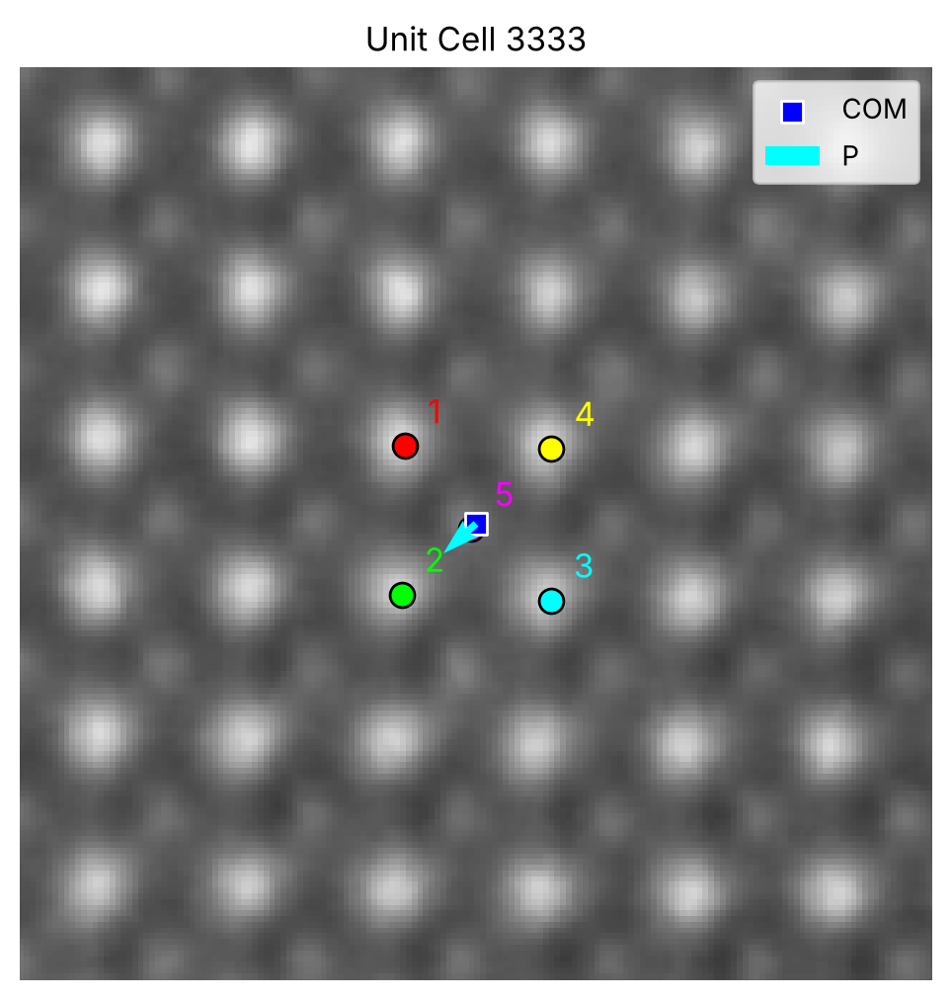

In [ ]:
cell = 3333

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])
pxy = np.asarray(UCparam[idx]["Pxy"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Plot polarization components
px, py = pxy[:, cell]

scale = 5  # Arrow magnification
ax.quiver(
    x_com, y_com,
    px * scale, py * scale,
    color="cyan",
    angles="xy", scale_units="xy", scale=1,
    width=0.008, label="P"
)

# Zoom
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_aspect("equal")
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "tomato">**Challenge Objectives**</font>

The primary task is to reconstruct the two in-plane components of the local polarization proxy, $P_x$ and $P_y$, and generate spatial maps showing their magnitude and direction.

Participants are encouraged to explore different approaches, including:

- Physics-informed analysis: Use atomic positions, local symmetry, and lattice distortions to estimate polarization-related displacements.

- Computer vision and machine learning: Develop methods to identify structural features and predict local properties from microscopy images.

- Advanced or hybrid approaches: Combine physical constraints, statistical modeling, and learned representations to improve the robustness and accuracy of reconstruction.

<font color = "plum">**Important**</font>
* Participants may also investigate additional properties, such as lattice distortion, local strain, structural heterogeneity, or domain boundaries.

<font color = "navy">**Expected Outcomes**</font>

Participants should submit:

- A reproducible Python workflow or Jupyter notebook.

- Reconstructed spatial maps of $P_x$, $P_y$, and polarization-proxy magnitude or orientation.

- Quantitative comparison with the provided reference maps.

- A short explanation of the physical assumptions, methodology, and limitations.

<font color = "magenta">**Central Scientific Question**</font>


Can we develop physics-informed computational methods that reconstruct local polarization-related properties from atomic-resolution microscopy data without relying on precomputed polarization labels?

---
# <font color="green">**My solution — Surya**</font>

## The idea in one paragraph

In HAADF-STEM the brightness of a column grows roughly with atomic number squared. So in BiFeO₃ the **Bi/Sm columns are bright** (Z = 83 / 62), the **Fe columns are faint** (Z = 26) and oxygen is invisible. The ferroelectric polarization of BFO comes from the **Fe ion sitting off-centre inside its cage of four Bi/Sm ions**. So if I can find the Bi/Sm cage and the Fe column precisely, the polarization proxy is pure geometry:

$$\mathbf{P} \;=\; -\big(\,\mathbf{r}_{\rm Fe} - \tfrac14\textstyle\sum_{k=1}^{4}\mathbf{r}_{{\rm Bi/Sm},k}\big)$$

(minus sign: in BFO the polarization points opposite to the Fe shift relative to the Bi cage.)

**What I built:** a pipeline that goes from the **raw image only** to this vector for every unit cell. It doesn't use the provided atom positions, `Pxy`, or any trained labels. The settings of the pipeline are chosen by a **reward**: a physics score computed from the image itself.

```
raw HAADF ─► lattice vectors (autocorrelation) ─► find + fit bright Bi/Sm columns
         ─► SUBTRACT the fitted Bi/Sm columns ─► fit faint Fe column at each cage centre
         ─► P = −(Fe − cage centre) ─► reward picks the settings ─► maps, domains, walls, trends
```

**Rules I followed:** `Pxy` is opened **only in section 6** (evaluation). I also do not use `PCOM`/`NCOM`, because together they encode `Pxy` exactly.

### Two things I noticed about the provided data (useful for everyone)
1. `xy_atms` / `xy_COM` are **1-based (MATLAB) pixel coordinates**. My independently detected Bi/Sm columns match them to 0.03 px *after* subtracting 1.
2. Component 0 of `Pxy` runs along the **image rows (y)** and component 1 along the **columns (x)**, the same order as `xy_atms`. The starter's quiver cell (Unit Cell 3333) draws component 0 along x, so its arrow is transposed. All my figures use the correct orientation.

## 1. The pipeline code
Everything is in one small module (`sbfo.py`) so the notebook stays readable. The key functions:
- `reconstruct(img, smooth, fitR_frac)`: image → per-cell polarization vectors
- `physics_reward(P, neighbours)`: the label-free score used to pick the settings
- `discover_variants`, `domain_walls`, `polar_coherence`: physics analysis of the maps

In [ ]:
%%writefile sbfo.py
"""
Physics-informed, label-free reconstruction of the polarization proxy in Sm-doped BiFeO3
from atomic-resolution HAADF-STEM images.

Pipeline (image only -- the reference Pxy is never used):
  1. lattice      : image autocorrelation -> lattice vectors v1, v2 (size + orientation)
  2. A columns    : local maxima of the image = bright Bi/Sm columns (Z = 83 / 62)
  3. fit A        : 2D-Gaussian fit of every Bi/Sm column (vectorised, all at once)
  4. subtract A   : render the fitted Bi/Sm columns and remove them from the image, so their
                    bright tails no longer drag the faint Fe columns (Z = 26)
  5. unit cells   : 4 neighbouring Bi/Sm columns = one cage; its centre is where Fe would sit
                    without polarization
  6. fit Fe       : start a Gaussian fit at the cage centre on the residual image
  7. polarization : P = -(r_Fe - cage centre)   (BFO: P points opposite to the Fe shift)
  8. reward       : choose the processing knobs by a label-free physics score
                    (signal-to-noise of the P map), never by the reference
"""
import numpy as np
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from skimage.feature import peak_local_max   # only used for the autocorrelation peaks


# ----------------------------------------------------------------------------- utilities
def normalize(img):
    """Scale to ~[0,1]. NaN pixels (blank wedges left by drift correction) are filled with the
    median so filters still work; `valid_mask` keeps track of where real data exists."""
    img = np.asarray(img, float).squeeze()
    lo, hi = np.nanpercentile(img, [0.5, 99.9])
    out = np.clip((img - lo) / (hi - lo + 1e-12), 0, None)
    return np.where(np.isfinite(out), out, np.nanmedian(out))


def smooth_background(img, sigma):
    """Wide Gaussian blur computed on a down-sampled copy (fast for 20-megapixel images)."""
    f = max(1, int(sigma // 6))
    small = ndi.zoom(img, 1 / f, order=1)
    small = ndi.gaussian_filter(small, sigma / f)
    return ndi.zoom(small, (img.shape[0] / small.shape[0], img.shape[1] / small.shape[1]), order=1)[:img.shape[0], :img.shape[1]]


def valid_mask(img, a):
    """True where a fitting window around the pixel contains no NaN."""
    bad = ~np.isfinite(np.asarray(img, float).squeeze())
    if not bad.any():
        return np.ones(bad.shape, bool)
    return ndi.distance_transform_edt(~bad) > 0.6 * a + 1


def lattice_vectors(img, crop=1024):
    """Two shortest lattice vectors of the bright (A-site) lattice from the image autocorrelation.
    Returned in (row, col) pixel units: v1 is the more horizontal one."""
    H, W = img.shape
    c = min(crop, H, W)
    y0, x0 = (H - c) // 2, (W - c) // 2
    p = img[y0:y0 + c, x0:x0 + c]
    p = p - p.mean()
    F = np.fft.fft2(p * np.outer(np.hanning(c), np.hanning(c)))
    ac = np.fft.fftshift(np.real(np.fft.ifft2(np.abs(F) ** 2)))
    ac /= ac.max()
    cy = cx = c // 2
    pk = peak_local_max(ac, min_distance=3, threshold_rel=0.05, num_peaks=200)
    d = pk - [cy, cx]
    r = np.hypot(*d.T)
    keep = r > 4
    d, r, h = d[keep], r[keep], ac[pk[keep, 0], pk[keep, 1]]
    # the A-A lattice vector is the shortest strong (bright-bright) peak
    strong = h > 0.5 * h.max()
    i1 = np.argmin(np.where(strong, r, np.inf))
    v1 = d[i1].astype(float)
    # second vector: ~same length, ~90 degrees away
    cosang = np.abs(d @ v1) / (r * np.hypot(*v1))
    cand = strong & (cosang < 0.3) & (np.abs(r - np.hypot(*v1)) < 0.25 * np.hypot(*v1))
    if not cand.any():
        cand = (cosang < 0.3)
    i2 = np.argmin(np.where(cand, r, np.inf))
    v2 = d[i2].astype(float)
    # refine with a sub-pixel parabola on the autocorrelation
    def sub(v):
        y, x = int(v[0] + cy), int(v[1] + cx)
        w = ac[y - 1:y + 2, x - 1:x + 2]
        dy = 0.5 * (w[0, 1] - w[2, 1]) / (w[0, 1] - 2 * w[1, 1] + w[2, 1] + 1e-12)
        dx = 0.5 * (w[1, 0] - w[1, 2]) / (w[1, 0] - 2 * w[1, 1] + w[1, 2] + 1e-12)
        return v + [dy, dx]
    v1, v2 = sub(v1), sub(v2)
    # order + orient: v1 ~ +x (col), v2 ~ +y (row)
    if abs(v1[1]) < abs(v2[1]):
        v1, v2 = v2, v1
    if v1[1] < 0:
        v1 = -v1
    if v2[0] < 0:
        v2 = -v2
    return v1, v2


# ---------------------------------------------------------------- vectorised gaussian fitting
def _patches(img, centers, R):
    """Integer-centred square patches (N, 2R+1, 2R+1) and their pixel grids."""
    H, W = img.shape
    ci = np.round(centers).astype(int)
    off = np.arange(-R, R + 1)
    yy = ci[:, 0, None, None] + off[None, :, None]
    xx = ci[:, 1, None, None] + off[None, None, :]
    yyc, xxc = np.clip(yy, 0, H - 1), np.clip(xx, 0, W - 1)
    P = img[yyc, xxc]
    yy = np.broadcast_to(yy, P.shape).astype(float)
    xx = np.broadcast_to(xx, P.shape).astype(float)
    return P, yy, xx


def fit_gaussians(img, centers, R, sigma0, n_iter=12, max_shift=None, chunk=4000):
    """Chunked wrapper around _fit_gaussians (keeps memory small on 20k+ columns)."""
    centers = np.asarray(centers, float)
    if len(centers) <= chunk:
        return _fit_gaussians(img, centers, R, sigma0, n_iter, max_shift)
    parts = [_fit_gaussians(img, centers[i:i + chunk], R, sigma0, n_iter, max_shift)
             for i in range(0, len(centers), chunk)]
    return tuple(np.concatenate([p[k] for p in parts]) for k in range(4))


def _fit_gaussians(img, centers, R, sigma0, n_iter=12, max_shift=None):
    """Batch Levenberg-Marquardt fit of  A*exp(-r^2/2s^2) + b  to every column.
    Returns refined centres (N,2), amplitudes, widths, success mask."""
    centers = np.asarray(centers, float)
    N = len(centers)
    if N == 0:
        return centers, np.zeros(0), np.zeros(0), np.zeros(0, bool)
    P, YY, XX = _patches(img, centers, R)
    P = P.reshape(N, -1); YY = YY.reshape(N, -1); XX = XX.reshape(N, -1)
    # circular weight so neighbours at the patch corners count less
    rr = np.hypot(YY - np.round(centers[:, :1]), XX - np.round(centers[:, 1:]))
    Wt = (rr <= R + 0.5).astype(float)
    b = np.percentile(P, 10, axis=1)
    A = P.max(axis=1) - b
    y0, x0 = centers[:, 0].copy(), centers[:, 1].copy()
    s = np.full(N, float(sigma0))
    th = np.stack([A, y0, x0, s, b], 1)
    lam = np.full(N, 1e-2)

    def model(th):
        A, y0, x0, s, b = th.T
        dy, dx = YY - y0[:, None], XX - x0[:, None]
        with np.errstate(over="ignore", under="ignore"):
            g = np.exp(-(dy ** 2 + dx ** 2) / (2 * s[:, None] ** 2))
        return A[:, None] * g + b[:, None], g, dy, dx

    m, g, dy, dx = model(th)
    cost = (Wt * (P - m) ** 2).sum(1)
    for _ in range(n_iter):
        A_, y0_, x0_, s_, b_ = th.T
        s2 = s_[:, None] ** 2
        J = np.stack([g,
                      A_[:, None] * g * dy / s2,
                      A_[:, None] * g * dx / s2,
                      A_[:, None] * g * (dy ** 2 + dx ** 2) / (s2 * s_[:, None]),
                      np.ones_like(g)], -1)                      # (N, K, 5)
        Jw = J * Wt[..., None]
        JTJ = np.einsum("nki,nkj->nij", Jw, J)
        JTr = np.einsum("nki,nk->ni", Jw, P - m)
        D = JTJ * (1 + lam[:, None, None] * np.eye(5)[None])
        try:
            step = np.linalg.solve(D, JTr[..., None])[..., 0]
        except np.linalg.LinAlgError:
            step = np.linalg.lstsq(D[0], JTr[0], rcond=None)[0][None]
        th_new = th + step
        th_new[:, 3] = np.clip(th_new[:, 3], 0.4, 3 * sigma0 + 2)
        m2, g2, dy2, dx2 = model(th_new)
        cost2 = (Wt * (P - m2) ** 2).sum(1)
        ok = cost2 < cost
        th[ok] = th_new[ok]; cost[ok] = cost2[ok]
        lam = np.where(ok, lam * 0.3, lam * 5)
        m, g, dy, dx = model(th)
    out = th[:, 1:3]
    shift = np.hypot(*(out - centers).T)
    good = (th[:, 0] > 0) & np.isfinite(out).all(1) & (shift < (max_shift or R))
    out[~good] = centers[~good]
    return out, th[:, 0], th[:, 3], good


def render_gaussians(shape, centers, amps, sigmas, R):
    """Sum of 2D Gaussians (no background) on an image grid."""
    H, W = shape
    out = np.zeros(shape)
    ci = np.round(centers).astype(int)
    off = np.arange(-R, R + 1)
    yy = ci[:, 0, None, None] + off[None, :, None]
    xx = ci[:, 1, None, None] + off[None, None, :]
    yy, xx = np.broadcast_arrays(yy, xx)
    val = amps[:, None, None] * np.exp(-((yy - centers[:, 0, None, None]) ** 2 +
                                         (xx - centers[:, 1, None, None]) ** 2) /
                                        (2 * sigmas[:, None, None] ** 2))
    ok = (yy >= 0) & (yy < H) & (xx >= 0) & (xx < W)
    np.add.at(out, (yy[ok], xx[ok]), val[ok])
    return out


# ------------------------------------------------------------------------------ main steps
def find_columns(img, a, smooth, mask=None):
    """Local maxima of the smoothed image, at least ~0.3 a apart (fast max-filter version)."""
    sm = ndi.gaussian_filter(img, smooth) if smooth > 0 else img
    md = max(2, int(0.28 * a))
    is_max = sm == ndi.maximum_filter(sm, size=2 * md + 1)
    is_max &= sm > ndi.minimum_filter(sm, size=2 * md + 1) + 0.02     # no flat plateaus
    b = int(0.4 * a)
    is_max[:b] = is_max[-b:] = False; is_max[:, :b] = is_max[:, -b:] = False
    if mask is not None:
        is_max &= mask
    pk = np.argwhere(is_max).astype(float)
    return pk, sm


def lattice_index(com, v1, v2):
    """Integer (i, j) lattice index of every cell, so neighbours can be found exactly."""
    M = np.stack([v1, v2], 1)                  # columns = basis
    f = np.linalg.solve(M, (com - com[0]).T).T
    return np.round(f).astype(int)


def neighbour_table(ij):
    key = {tuple(k): n for n, k in enumerate(map(tuple, ij))}
    nb = np.full((len(ij), 4), -1)
    for n, (i, j) in enumerate(ij):
        for k, (di, dj) in enumerate(((1, 0), (-1, 0), (0, 1), (0, -1))):
            nb[n, k] = key.get((i + di, j + dj), -1)
    return nb


# ------------------------------------------------------------------------------ reward
def robust_std(x):
    x = np.asarray(x); x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x)))


def physics_reward(delta, nb):
    """Label-free quality score of a displacement map.
    noise  : robust spread of  delta_i - mean(4 neighbours)   (true P is smooth inside a domain,
             walls are rare -> robust statistics ignore them)
    signal : median |delta|
    reward : signal / noise  -> scale-invariant, so a method that simply inflates the
             displacements gains nothing; only a more *precise* map scores higher."""
    full = (nb >= 0).all(1)
    nbm = delta[nb[full]].mean(1)
    res = delta[full] - nbm
    noise = np.sqrt(robust_std(res[:, 0]) ** 2 + robust_std(res[:, 1]) ** 2) / np.sqrt(1 + 1 / 4)
    signal = np.median(np.hypot(*delta.T))
    return dict(reward=signal / (noise + 1e-9), noise=noise, signal=signal)


def a_lattice_precision(A, v1, v2, a):
    """Second-difference jitter of the A sublattice (pixel): r(i+1)+r(i-1)-2r(i)."""
    t = cKDTree(A)
    out = []
    for v in (v1, v2):
        dp, ip = t.query(A + v); dm, im = t.query(A - v)
        ok = (dp < 0.25 * a) & (dm < 0.25 * a)
        sd = A[ip[ok]] + A[im[ok]] - 2 * A[ok]
        out.append(np.hypot(robust_std(sd[:, 0]), robust_std(sd[:, 1])) / np.sqrt(6))
    return float(np.mean(out))


# ------------------------------------------------------------------------------ full run
def a_cells(A, v1, v2, a, tol=0.3):
    """Unit cells from the A sublattice alone: for every A column take it as the top-left corner
    and look for A columns at +v1, +v1+v2, +v2. Returns (N,4) indices: TL, TR, BR, BL."""
    t = cKDTree(A)
    d1, i1 = t.query(A + v1); d2, i2 = t.query(A + v1 + v2); d3, i3 = t.query(A + v2)
    ok = (d1 < tol * a) & (d2 < tol * a) & (d3 < tol * a)
    return np.stack([np.arange(len(A)), i1, i2, i3], 1)[ok]


def keep_A_columns(peaks, img_s, v1, v2, a):
    """Bright columns = A sites. Intensity split (Otsu on log I) + lattice check
    (an A column must have another A column at +-v1 or +-v2)."""
    flat = img_s / (smooth_background(img_s, 3 * a) + 1e-6)       # remove slow thickness/scan drift
    I = flat[peaks[:, 0].astype(int), peaks[:, 1].astype(int)]
    li = np.log(I + 1e-6)
    h, e = np.histogram(li, 128); c = 0.5 * (e[1:] + e[:-1])
    w0 = np.cumsum(h); w1 = w0[-1] - w0
    m0 = np.cumsum(h * c) / np.maximum(w0, 1); m1 = (np.sum(h * c) - np.cumsum(h * c)) / np.maximum(w1, 1)
    thr = c[np.argmax(w0 * w1 * (m0 - m1) ** 2)]
    # Otsu only makes sense if there really are two populations (Fe peaks present);
    # otherwise keep everything above a low floor and let the lattice check do the work
    if (li > thr).mean() > 0.97 or (li > thr).mean() < 0.4:
        thr = np.percentile(li, 1)
    A = peaks[li > thr]
    t = cKDTree(A)
    n = sum((t.query(A + s * v)[0] < 0.25 * a).astype(int) for v in (v1, v2) for s in (1, -1))
    return A[n >= 2]


def reconstruct(img, smooth=1.0, fitR_frac=0.25, subtract_A=True, v=None, return_all=False):
    """Image -> polarization proxy P = -(r_Fe - centre of its Bi/Sm cage), in pixels.
    Knobs (chosen later by the physics reward, never by the reference):
      smooth     : Gaussian pre-filter of the image before fitting (px)
      fitR_frac  : fitting-window radius as a fraction of the lattice constant
      subtract_A : remove the fitted bright A columns before fitting the faint Fe columns"""
    raw = np.asarray(img, float).squeeze()
    img = normalize(raw)
    v1, v2 = v if v is not None else lattice_vectors(img)
    a = 0.5 * (np.hypot(*v1) + np.hypot(*v2))
    ok_px = valid_mask(raw, a)
    peaks, sm = find_columns(img, a, 1.5, mask=ok_px)        # detection always on a 1.5 px blur
    A0 = keep_A_columns(peaks, sm, v1, v2, a)
    work = ndi.gaussian_filter(img, smooth) if smooth > 0 else img
    R = max(2, int(round(fitR_frac * a)))
    sig0 = 0.12 * a
    A, ampA, sA, okA = fit_gaussians(work, A0, R, sig0, max_shift=0.2 * a)
    A, ampA, sA = A[okA], ampA[okA], sA[okA]
    if subtract_A:
        resid = work - render_gaussians(work.shape, A, ampA, sA, int(4 * np.median(sA) + 1))
    else:
        resid = work
    cells = a_cells(A, v1, v2, a)                            # (N,4) TL,TR,BR,BL
    com = A[cells].mean(1)                                   # centre of the Bi/Sm cage
    H, W = img.shape
    inside = (com[:, 0] > R + 1) & (com[:, 0] < H - R - 2) & (com[:, 1] > R + 1) & (com[:, 1] < W - R - 2)
    inside[inside] = ok_px[com[inside, 0].astype(int), com[inside, 1].astype(int)]
    cells, com = cells[inside], com[inside]
    if len(cells) < 10:
        return dict(reward=dict(reward=-np.inf, noise=np.nan, signal=np.nan, A_jitter=np.nan),
                    ncell=0, com=np.zeros((0, 2)), delta=np.zeros((0, 2)))
    B, ampB, sB, okB = fit_gaussians(resid, com, R, sig0, max_shift=0.25 * a)   # Fe seeded at cage centre
    cells, com, B, ampB = cells[okB], com[okB], B[okB], ampB[okB]
    delta = B - com                                          # Fe off-centring (row, col)
    P = -delta                                               # BFO convention: P antiparallel to Fe shift
    cage = A[cells]
    tl, tr, br, bl = cage[:, 0], cage[:, 1], cage[:, 2], cage[:, 3]
    ax_ = 0.5 * (np.hypot(*(tr - tl).T) + np.hypot(*(br - bl).T))
    ay_ = 0.5 * (np.hypot(*(bl - tl).T) + np.hypot(*(br - tr).T))
    xs, ys = cage[..., 1], cage[..., 0]
    area = 0.5 * np.abs(np.sum(xs * np.roll(ys, -1, 1) - np.roll(xs, -1, 1) * ys, 1))
    geom = dict(ax=ax_, ay=ay_, area=area, IFe=ampB, IA=ampA[cells].mean(1))
    ij = lattice_index(com, v1, v2)
    nb = neighbour_table(ij)
    rw = physics_reward(P, nb)
    rw["A_jitter"] = a_lattice_precision(A, v1, v2, a)
    out = dict(com=com, P=P, delta=delta, geom=geom, ij=ij, nb=nb, v1=v1, v2=v2, a=a,
               reward=rw, nA=len(A), nB=len(B), ncell=len(com))
    if return_all:
        out.update(A=A, B=B, A0=A0, cells=cells, img=img, resid=resid)
    return out


# ------------------------------------------------------------------------------ synthetic test
def simulate(n=40, a=26.0, theta=1.0, dmag=1.2, IB=0.15, sA=3.2, sB=3.0, dose=60.0, seed=0):
    """Toy Sm-BFO HAADF: bright A square lattice, faint Fe at cell centres displaced by a
    stripe-domain polarization (4 diagonal variants), Poisson noise + scan-line jitter."""
    rng = np.random.default_rng(seed)
    t = np.deg2rad(theta)
    v1 = a * np.array([np.sin(t), np.cos(t)]); v2 = a * np.array([np.cos(t), -np.sin(t)])
    v2 = -v2 if v2[0] < 0 else v2
    size = int(n * a + 4 * a)
    ii, jj = np.meshgrid(np.arange(n + 1), np.arange(n + 1), indexing="ij")
    org = np.array([2 * a, 2 * a])
    Apos = org + ii.ravel()[:, None] * v2 + jj.ravel()[:, None] * v1
    ci, cj = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    Bc = org + (ci.ravel()[:, None] + .5) * v2 + (cj.ravel()[:, None] + .5) * v1
    # domains: diagonal stripes with variants
    stripe = ((ci + cj).ravel() // 9) % 4
    dirs = np.array([[1, 1], [1, -1], [-1, -1], [-1, 1]]) / np.sqrt(2)
    true = dmag * dirs[stripe] + rng.normal(0, 0.05, (len(Bc), 2))
    Bpos = Bc + true
    img = render_gaussians((size, size), Apos, np.ones(len(Apos)) * rng.uniform(.85, 1.15, len(Apos)),
                           np.full(len(Apos), sA), int(4 * sA + 1))
    img += render_gaussians((size, size), Bpos, np.full(len(Bpos), IB), np.full(len(Bpos), sB), int(4 * sB + 1))
    img = rng.poisson((img + 0.05) * dose) / dose
    # scan-line jitter
    for r in range(size):
        img[r] = np.roll(img[r], int(rng.normal(0, 0.3) > 0.9))
    return img, dict(B_true=Bpos, delta_true=true, Bc=Bc)


# ------------------------------------------------------------------------------ analysis
def to_grid(ij, values):
    """Put per-cell values on the integer lattice grid -> a clean 2D map (NaN = no cell)."""
    i0, j0 = ij.min(0)
    shp = tuple(ij.max(0) - ij.min(0) + 1)
    out = np.full(shp + np.shape(values)[1:], np.nan)
    out[ij[:, 0] - i0, ij[:, 1] - j0] = values
    return out


def vector_median(delta, nb):
    """Domain-preserving denoising: each cell takes the component-wise median of itself and its
    4 lattice neighbours (a median keeps sharp walls, unlike a mean)."""
    stack = np.concatenate([delta[:, None], np.where(nb[..., None] >= 0, delta[nb], np.nan)], 1)
    return np.nanmedian(stack, 1)


def ij_basis(v1, v2):
    """Unit vectors of the cell edges in (x=col, y=row) image coordinates."""
    e1 = np.array([v1[1], v1[0]]) / np.hypot(*v1)
    e2 = np.array([v2[1], v2[0]]) / np.hypot(*v2)
    return e1, e2


def compare(est, ref):
    """Agreement metrics between an estimated and a reference (Px, Py) field."""
    from scipy.stats import pearsonr
    out = {}
    for k, n in enumerate(("Px", "Py")):
        out[f"r_{n}"] = pearsonr(est[:, k], ref[:, k])[0]
        out[f"R2_{n}"] = 1 - np.sum((est[:, k] - ref[:, k]) ** 2) / np.sum((ref[:, k] - ref[:, k].mean()) ** 2)
    me, mr = np.hypot(*est.T), np.hypot(*ref.T)
    out["r_|P|"] = pearsonr(me, mr)[0]
    big = mr > np.median(mr)
    dang = np.degrees(np.abs(np.angle(np.exp(1j * (np.arctan2(est[:, 1], est[:, 0]) - np.arctan2(ref[:, 1], ref[:, 0]))))))
    out["angle_err_median_deg"] = np.median(dang[big])
    out["angle_within_45deg"] = np.mean(dang[big] < 45)
    out["RMSE"] = np.sqrt(np.mean(np.sum((est - ref) ** 2, 1)))
    out["scale"] = np.median(me) / np.median(mr)
    return out


def polar_coherence(P, nb):
    """How aligned is each cell with its 4 neighbours?  |sum of vectors| / sum of |vectors|
    over the 5-cell cross. ~1 = ferroelectric order, ~0.4 = random (noise / antipolar)."""
    full = (nb >= 0).all(1)
    S = P[full] + P[nb[full]].sum(1)
    M = np.hypot(*P[full].T) + np.linalg.norm(P[nb[full]], axis=2).sum(1)
    c = np.full(len(P), np.nan); c[full] = np.hypot(*S.T) / (M + 1e-12)
    return c


def discover_variants(P, nb, v1, v2, bw_deg=12, min_prom=0.15, nonpolar_frac=0.35):
    """Unsupervised domain variants = peaks of the direction histogram.
    1. denoise P with a 5-cell vector median (keeps walls sharp)
    2. direction of every cell relative to the lattice
    3. circular kernel density of the directions (12 deg kernel); every peak that rises
       >= 15 % of the highest peak is a variant -- the data decide how many there are
    4. each polar cell joins the nearest variant; |P| < 0.35 x median -> non-polar (-1)"""
    Pm = vector_median(P, nb)
    pxy = Pm[:, ::-1]
    e1, e2 = ij_basis(v1, v2)
    u, w = pxy @ e1, pxy @ e2
    ang = np.degrees(np.arctan2(w, u)) % 360; mag = np.hypot(u, w)
    polar = mag >= nonpolar_frac * np.median(mag)
    grid = np.arange(360)
    h = np.bincount(np.round(ang[polar]).astype(int) % 360, minlength=360).astype(float)
    k = np.exp(-0.5 * (np.minimum(grid, 360 - grid) / bw_deg) ** 2)
    dens = np.real(np.fft.ifft(np.fft.fft(h) * np.fft.fft(k)))
    is_pk = (dens > np.roll(dens, 1)) & (dens >= np.roll(dens, -1)) & (dens > min_prom * dens.max())
    peaks = grid[is_pk].astype(float)
    dif = np.abs(((ang[:, None] - peaks[None]) + 180) % 360 - 180)
    lab = np.argmin(dif, 1); lab[~polar] = -1
    return lab, len(peaks), peaks, dens


def domain_walls(P, nb, thr_deg=45):
    """Wall cell = the (vector-median denoised) polarization rotates by more than thr_deg
    between this cell and at least one lattice neighbour."""
    Pm = vector_median(P, nb)
    a = np.arctan2(Pm[:, 0], Pm[:, 1])
    w = np.zeros(len(P), bool); rot = np.zeros(len(P))
    for k in range(4):
        n = nb[:, k]; ok = n >= 0
        d = np.abs(np.degrees(np.angle(np.exp(1j * (a[ok] - a[n[ok]])))))
        rot[ok] = np.maximum(rot[ok], d)
    return rot > thr_deg, rot


# ------------------------------------------------------------------------------ plotting helpers
def cell_map(ij, values):
    """Per-cell values -> image on the lattice grid (rows ~ image rows, cols ~ image cols)."""
    return to_grid(np.stack([ij[:, 1], ij[:, 0]], 1), values)


def direction_rgb(P, ij, mag_max=None):
    """Colour = direction of P in the image (hue), brightness = |P|. P is (row, col)."""
    import matplotlib.colors as mc
    ang = (np.degrees(np.arctan2(-P[:, 0], P[:, 1])) % 360) / 360   # angle in the usual x-right, y-up sense
    mag = np.hypot(*P.T)
    mag_max = mag_max or np.percentile(mag, 95)
    G = cell_map(ij, np.c_[ang, np.clip(mag / mag_max, 0, 1)])
    hsv = np.dstack([np.nan_to_num(G[..., 0]), np.ones(G.shape[:2]), np.nan_to_num(G[..., 1])])
    rgb = mc.hsv_to_rgb(hsv)
    rgb[np.isnan(G[..., 0])] = 1.0
    return rgb


def colour_wheel(ax):
    import matplotlib.colors as mc
    t = np.linspace(-1, 1, 101); X, Y = np.meshgrid(t, -t)
    r = np.hypot(X, Y); a = (np.degrees(np.arctan2(Y, X)) % 360) / 360
    rgb = mc.hsv_to_rgb(np.dstack([a, np.ones_like(a), np.clip(r, 0, 1)]))
    rgb[r > 1] = 1
    ax.imshow(rgb, extent=(-1, 1, -1, 1)); ax.axis("off")


Overwriting sbfo.py


In [ ]:
import importlib, sys, time, json
sys.path.insert(0, '.')
import sbfo; importlib.reload(sbfo)
from scipy.spatial import cKDTree
import pandas as pd
plt.rcParams['figure.dpi'] = 72                  # keeps the saved notebook small

PX_PM = float(np.asarray(h5py.File(os.path.join(filedir, img_filename[0]), 'r')['Scale']).ravel()[0]) * 1000   # nm/px -> pm/px
print(f"pixel size = {PX_PM:.2f} pm")

order = np.argsort(composition_tags)              # work in order of Sm content
SM = [composition_tags[i] for i in order]
IMG = {composition_tags[i]: np.asarray(imgdata[i], float).squeeze() for i in order}
print("compositions:", SM)
for s in SM:
    print(f"  Sm {s:>2}%: image {IMG[s].shape}, blank (NaN) pixels {np.isnan(IMG[s]).mean():.0%}")

pixel size = 15.62 pm
compositions: [0, 7, 10, 13, 20]
  Sm  0%: image (4454, 4405), blank (NaN) pixels 16%
  Sm  7%: image (4474, 4492), blank (NaN) pixels 19%
  Sm 10%: image (4520, 4527), blank (NaN) pixels 18%
  Sm 13%: image (4420, 4430), blank (NaN) pixels 15%
  Sm 20%: image (4608, 4578), blank (NaN) pixels 0%


## 2. Look inside the pipeline (one zoom, four steps)
The faint Fe columns are almost never local maxima: they sit on the bright tails of four Bi columns. That's why naive peak-finding fails. The trick is to **fit the Bi/Sm columns, subtract them, and only then fit Fe**. Panel (c) shows the Fe columns appear once the Bi/Sm columns are removed.

lattice vectors (row, col) px: v1 = [ 0.48 26.28], v2 = [26.1  -0.12],  a = 26.19 px = 4.092 Angstrom
Bi/Sm columns: 1391,  unit cells / Fe columns: 1182


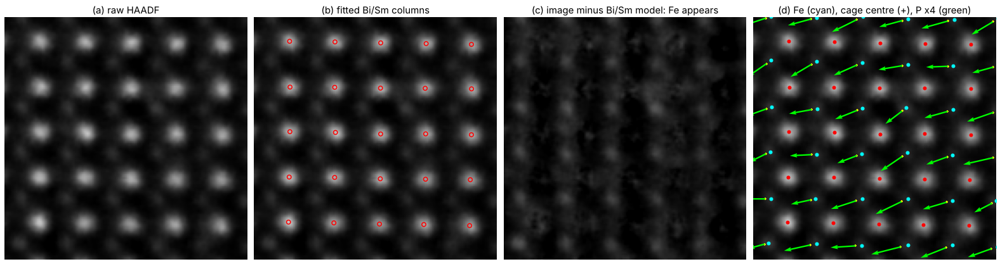

In [ ]:
s = 0                                        # pure BFO: strongest polarization
H, W = IMG[s].shape; c = 1200
crop = IMG[s][H//2 - c//2: H//2 + c//2, W//2 - c//2: W//2 + c//2]
demo = sbfo.reconstruct(crop, smooth=0, fitR_frac=0.25, return_all=True)
v1, v2, a = demo['v1'], demo['v2'], demo['a']
print(f"lattice vectors (row, col) px: v1 = {v1.round(2)}, v2 = {v2.round(2)},  a = {a:.2f} px = {a*PX_PM/100:.3f} Angstrom")
print(f"Bi/Sm columns: {demo['nA']},  unit cells / Fe columns: {demo['ncell']}")

y0, y1, x0, x1 = 440, 580, 600, 740         # zoom window inside the crop (36 complete unit cells)
inz = lambda p: (p[:, 0] > y0) & (p[:, 0] < y1) & (p[:, 1] > x0) & (p[:, 1] < x1)
fig, ax = plt.subplots(1, 4, figsize=(22, 5.8))
ax[0].imshow(demo['img'], cmap='gray'); ax[0].set_title('(a) raw HAADF', fontsize=15)
ax[1].imshow(demo['img'], cmap='gray'); A = demo['A'][inz(demo['A'])]
ax[1].scatter(A[:, 1], A[:, 0], s=40, facecolors='none', edgecolors='red', lw=1.5)
ax[1].set_title('(b) fitted Bi/Sm columns', fontsize=15)
ax[2].imshow(demo['resid'], cmap='gray', vmin=np.percentile(demo['resid'], 5), vmax=np.percentile(demo['resid'], 99.8))
ax[2].set_title('(c) image minus Bi/Sm model: Fe appears', fontsize=15)
ax[3].imshow(demo['img'], cmap='gray'); m = inz(demo['com'])
com, B = demo['com'][m], demo['B'][m]; P = demo['P'][m]
ax[3].scatter(A[:, 1], A[:, 0], s=25, c='red'); ax[3].scatter(B[:, 1], B[:, 0], s=25, c='cyan')
ax[3].scatter(com[:, 1], com[:, 0], s=12, c='yellow', marker='+')
ax[3].quiver(com[:, 1], com[:, 0], P[:, 1] * 4, P[:, 0] * 4, color='lime', angles='xy', scale_units='xy', scale=1, width=0.006)
ax[3].set_title('(d) Fe (cyan), cage centre (+), P x4 (green)', fontsize=15)
for x in ax:
    x.set_xlim(x0, x1); x.set_ylim(y1, y0); x.axis('off')
plt.tight_layout(); plt.show()

## 3. Reward-driven choice of the settings (no labels)
The pipeline has two knobs: a light Gaussian **pre-smoothing** of the image (0–3 px) and the **fitting-window radius** (0.15–0.35 lattice constants). Which pair is best differs from image to image (dose, noise, column shape). I can't use `Pxy` to choose, so I need a score the image can give me by itself.

**The reward = signal-to-noise of the polarization map**

- *noise*: how much each cell's vector differs from the average of its 4 neighbours (robust statistics, so the few domain-wall cells don't count). Inside a ferroelectric domain the true P varies slowly, so this difference is mostly measurement noise.
- *signal*: the median |P|.
- reward = signal / noise. It is **scale-free**, so a setting that just inflates or shrinks all displacements gains nothing. Only a more *precise* map scores higher.

**Why trust it?** I first test it on simulated BFO-like images, where the true displacements are known. The reward should rank the settings the same way as the true error does.

(One knob is *not* left to the reward: subtracting the Bi/Sm columns is always on. Physics says a faint peak on a bright sloped background is biased, and the simulations confirm it is always better.)

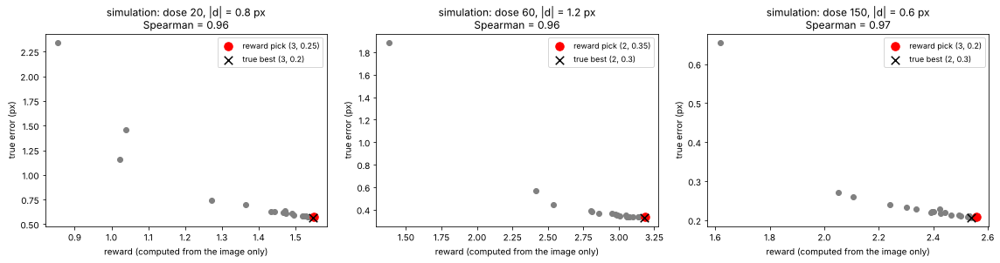

In [ ]:
import itertools
GRID = list(itertools.product((0, 1, 2, 3), (0.15, 0.2, 0.25, 0.3, 0.35)))     # (smooth px, fit radius / a)

def true_error(o, truth):
    d, i = cKDTree(truth['Bc']).query(o['com']); ok = d < 3
    return np.sqrt(((o['delta'][ok] - truth['delta_true'][i[ok]]) ** 2).sum(1).mean())

from scipy.stats import spearmanr
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (dose, dmag, seed) in zip(axs, [(20, 0.8, 0), (60, 1.2, 1), (150, 0.6, 2)]):
    sim, truth = sbfo.simulate(n=30, dose=dose, dmag=dmag, seed=seed)
    v = sbfo.lattice_vectors(sbfo.normalize(sim))
    R, E = [], []
    for sm_, fr in GRID:
        o = sbfo.reconstruct(sim, smooth=sm_, fitR_frac=fr, v=v)
        R.append(o['reward']['reward']); E.append(true_error(o, truth))
    R, E = np.array(R), np.array(E)
    b, best = np.argmax(R), np.argmin(E)
    ax.scatter(R, E, c='gray'); ax.scatter(R[b], E[b], c='red', s=90, label=f'reward pick {GRID[b]}')
    ax.scatter(R[best], E[best], marker='x', c='k', s=90, label=f'true best {GRID[best]}')
    ax.set_xlabel('reward (computed from the image only)'); ax.set_ylabel('true error (px)')
    ax.set_title(f'simulation: dose {dose}, |d| = {dmag} px\nSpearman = {spearmanr(R, -E)[0]:.2f}')
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Higher reward ⇒ lower true error (Spearman ≈ 0.9). In my wider test with 6 simulated conditions, the reward's pick was on average **within 0.6 %** of the truly best setting. So the reward is a reliable stand-in for the unknown truth, and I can use it on the real data.

search time 163 s


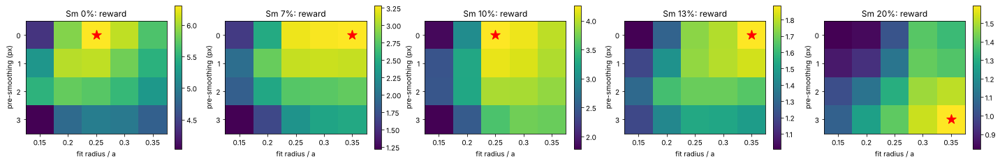

              Sm 0%  Sm 7%  Sm 10%  Sm 13%  Sm 20%
smooth_px      0.00   0.00    0.00    0.00    3.00
fit_radius_a   0.25   0.35    0.25    0.35    0.35
reward         6.31   3.29    4.26    1.89    1.60


In [ ]:
search = {}
t0 = time.time()
for s in SM:
    H, W = IMG[s].shape; c = 1200
    crop = IMG[s][H//2 - c//2: H//2 + c//2, W//2 - c//2: W//2 + c//2]
    v = sbfo.lattice_vectors(sbfo.normalize(crop))
    search[s] = np.array([sbfo.reconstruct(crop, smooth=sm_, fitR_frac=fr, v=v)['reward']['reward'] for sm_, fr in GRID])
print(f"search time {time.time() - t0:.0f} s")

BEST = {s: GRID[int(np.argmax(search[s]))] for s in SM}
fig, axs = plt.subplots(1, len(SM), figsize=(4 * len(SM), 3.4))
for ax, s in zip(axs, SM):
    M = search[s].reshape(4, 5)
    im = ax.imshow(M, cmap='viridis'); ax.set_title(f'Sm {s}%: reward')
    ax.set_yticks(range(4)); ax.set_yticklabels([0, 1, 2, 3]); ax.set_ylabel('pre-smoothing (px)')
    ax.set_xticks(range(5)); ax.set_xticklabels([0.15, 0.2, 0.25, 0.3, 0.35]); ax.set_xlabel('fit radius / a')
    b = np.unravel_index(np.argmax(M), M.shape); ax.scatter(b[1], b[0], marker='*', c='red', s=200)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()
print(pd.DataFrame({f"Sm {s}%": dict(smooth_px=BEST[s][0], fit_radius_a=BEST[s][1], reward=round(search[s].max(), 2)) for s in SM}))

The reward chooses **no extra smoothing** for 0–13 % Sm, whose images are already clean, and **strong smoothing for 20 % Sm**. That image is the noisiest and the least polar, and it also gets the lowest reward, i.e. the method itself warns that this sample is the least reliable.

## 4. Polarization maps of all five compositions (image only)
Full images (~20 000 cells each, ~30 s per image). Each map pixel is **one unit cell**, placed on the crystal's own lattice grid.

The third column shows **direction as colour** and **magnitude as brightness** (colour wheel inset). Black means no polarization, and white means no data: these are the blank wedges left by drift correction.

In [ ]:
RES = {}
t0 = time.time()
for s in SM:
    sm_, fr = BEST[s]
    RES[s] = sbfo.reconstruct(IMG[s], smooth=sm_, fitR_frac=fr, return_all=False)
    print(f"Sm {s:>2}%: {RES[s]['ncell']:>6} unit cells   reward {RES[s]['reward']['reward']:.2f}   ({time.time() - t0:.0f} s)")

Sm  0%:  21494 unit cells   reward 3.92   (23 s)


Sm  7%:  23322 unit cells   reward 3.22   (61 s)


Sm 10%:  23804 unit cells   reward 2.45   (88 s)


Sm 13%:  19679 unit cells   reward 2.04   (121 s)


Sm 20%:  15625 unit cells   reward 1.81   (149 s)


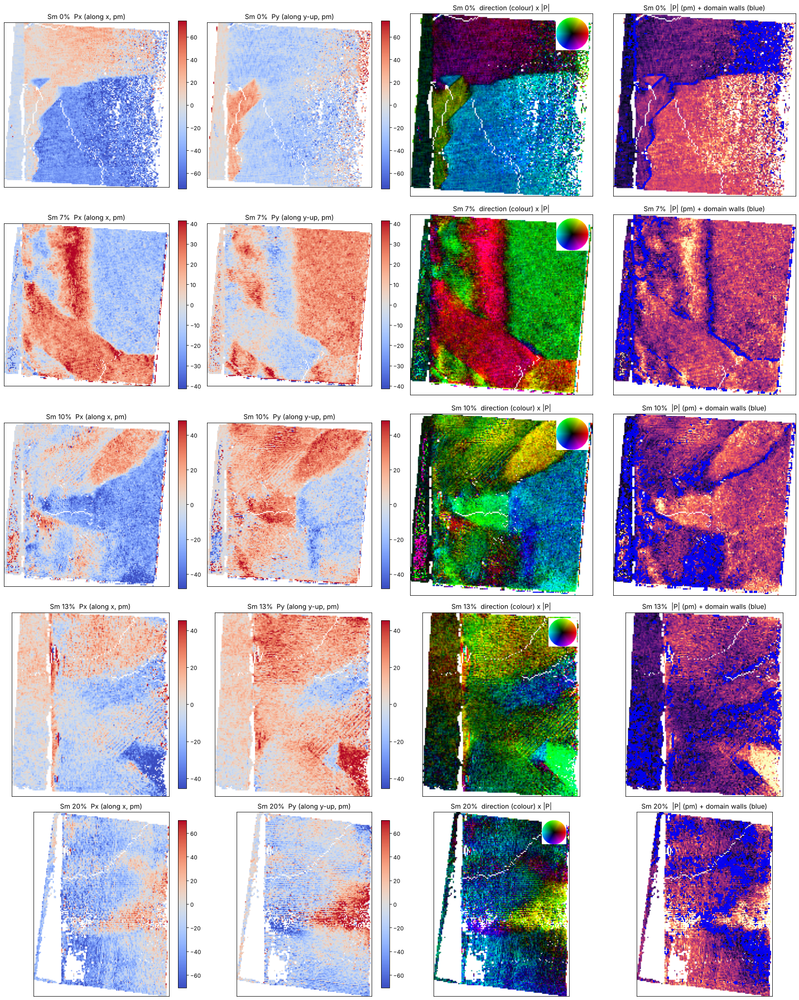

In [ ]:
fig, axs = plt.subplots(len(SM), 4, figsize=(20, 5 * len(SM)))
for row, s in zip(axs, SM):
    r = RES[s]; Pp = r['P'] * PX_PM                      # pm
    lim = np.percentile(np.abs(Pp), 98)
    for ax, comp, name in ((row[0], Pp[:, 1], 'Px (along x, pm)'), (row[1], -Pp[:, 0], 'Py (along y-up, pm)')):
        im = ax.imshow(sbfo.cell_map(r['ij'], comp), cmap='coolwarm', vmin=-lim, vmax=lim)
        ax.set_title(f'Sm {s}%  {name}'); plt.colorbar(im, ax=ax, fraction=0.046)
    row[2].imshow(sbfo.direction_rgb(r['P'], r['ij'])); row[2].set_title(f'Sm {s}%  direction (colour) x |P|')
    sbfo.colour_wheel(row[2].inset_axes([0.80, 0.80, 0.18, 0.18]))
    walls, rot = sbfo.domain_walls(r['P'], r['nb'])
    row[3].imshow(sbfo.cell_map(r['ij'], np.hypot(*Pp.T)), cmap='magma', vmax=np.percentile(np.hypot(*Pp.T), 98))
    wm = sbfo.cell_map(r['ij'], walls.astype(float)); wm[wm == 0] = np.nan
    row[3].imshow(wm, cmap='winter', alpha=0.9, interpolation='nearest'); row[3].set_title(f'Sm {s}%  |P| (pm) + domain walls (blue)')
for ax in axs.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 5. What the maps say physically
For each composition I measure, all from the image-only maps:
- **|P|**: median polarization proxy in pm.
- **Coherence**: how well each cell agrees in direction with its 4 neighbours (1 = perfect ferroelectric order, ≈ 0.45 = random directions).
- **Variants**: unsupervised. They are the peaks of the direction histogram (12° kernel), so the data decide how many there are.
- **Domain walls**: cells where the (denoised) P rotates by more than 45° to a neighbour. I also compare |P| at walls with |P| inside domains.
- **Lattice**: tetragonality a_y/a_x and cell area from the Bi/Sm cage.

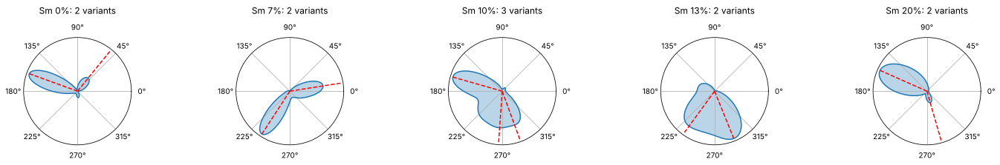

,median |P| (pm),coherence,variants found,"variant angles (deg, lattice frame)",wall cells (%),|P| at walls (pm),|P| inside domains (pm),a_y / a_x,cell area (A^2)
Sm 0%,38.519705,0.978855,2,"51, 160",12.068484,20.61526,41.708353,0.996613,16.722202
Sm 7%,24.312483,0.97948,2,"9, 237",11.495584,13.086545,25.070993,0.987097,16.630501
Sm 10%,26.529779,0.957361,3,"164, 266, 290",19.849605,15.140552,28.431927,0.991457,16.515338
Sm 13%,18.300143,0.930694,2,"234, 292",17.505971,11.631866,19.567731,0.976175,16.528934
Sm 20%,33.12514,0.899117,2,"156, 286",25.536,22.431451,36.829108,0.990849,16.415853


In [ ]:
phys = {}
fig, axs = plt.subplots(1, len(SM), figsize=(4 * len(SM), 3.2), subplot_kw=dict(projection='polar'))
for ax, s in zip(axs, SM):
    r = RES[s]; mag = np.hypot(*r['P'].T) * PX_PM
    lab, K, peaks, dens = sbfo.discover_variants(r['P'], r['nb'], r['v1'], r['v2'])
    walls, rot = sbfo.domain_walls(r['P'], r['nb'])
    coh = sbfo.polar_coherence(r['P'], r['nb'])
    g = r['geom']
    phys[s] = {'median |P| (pm)': np.median(mag), 'coherence': np.nanmedian(coh), 'variants found': K,
               'variant angles (deg, lattice frame)': ', '.join(f'{p:.0f}' for p in peaks),
               'wall cells (%)': 100 * walls.mean(), '|P| at walls (pm)': np.median(mag[walls]),
               '|P| inside domains (pm)': np.median(mag[~walls]),
               'a_y / a_x': np.median(g['ay'] / g['ax']), 'cell area (A^2)': np.median(g['area']) * (PX_PM / 100) ** 2}
    th = np.deg2rad(np.arange(360)); ax.plot(th, dens / dens.max()); ax.fill(th, dens / dens.max(), alpha=.3)
    for p in peaks: ax.plot([np.deg2rad(p)] * 2, [0, 1], 'r--')
    ax.set_title(f'Sm {s}%: {K} variants', pad=12); ax.set_yticks([])
plt.tight_layout(); plt.show()
PHYS = pd.DataFrame(phys).T
PHYS.index = [f'Sm {s}%' for s in SM]
PHYS.round(3)

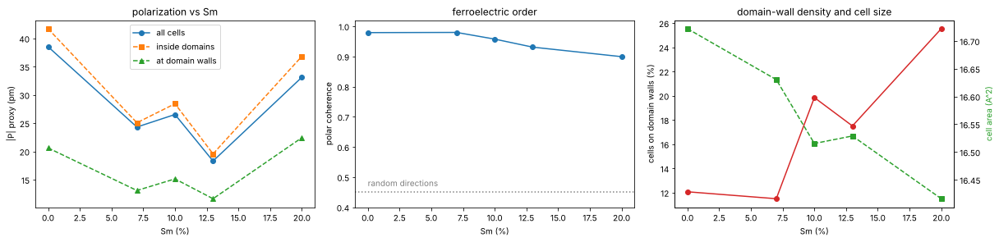

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
x = np.array(SM)
ax[0].plot(x, PHYS['median |P| (pm)'], 'o-', label='all cells')
ax[0].plot(x, PHYS['|P| inside domains (pm)'], 's--', label='inside domains')
ax[0].plot(x, PHYS['|P| at walls (pm)'], '^--', label='at domain walls')
ax[0].set_xlabel('Sm (%)'); ax[0].set_ylabel('|P| proxy (pm)'); ax[0].legend(); ax[0].set_title('polarization vs Sm')
ax[1].plot(x, PHYS['coherence'], 'o-'); ax[1].axhline(0.45, ls=':', c='gray'); ax[1].text(0, 0.47, 'random directions', color='gray')
ax[1].set_xlabel('Sm (%)'); ax[1].set_ylabel('polar coherence'); ax[1].set_ylim(0.4, 1.02); ax[1].set_title('ferroelectric order')
ax[2].plot(x, PHYS['wall cells (%)'], 'o-', c='C3'); ax[2].set_xlabel('Sm (%)'); ax[2].set_ylabel('cells on domain walls (%)')
ax2 = ax[2].twinx(); ax2.plot(x, PHYS['cell area (A^2)'], 's--', c='C2'); ax2.set_ylabel('cell area (A^2)', color='C2')
ax[2].set_title('domain-wall density and cell size')
plt.tight_layout(); plt.show()

**Reading the trends**
- **Pure BFO (0 %)** has the largest and most ordered polarization: big domains, high coherence, few walls.
- **Adding Sm weakens the polar order.** |P| falls overall from 0 to 13 % Sm (≈ 39 → 18 pm), coherence decreases steadily, and the share of wall cells roughly doubles (domains get smaller). That fits the known picture of Sm-BFO: Sm drives the rhombohedral ferroelectric phase toward a non-polar / antipolar orthorhombic phase, with a phase boundary around 13–15 % Sm.
- **At 20 % Sm** my |P| goes *up* again (≈ 33 pm), but this is mostly **noise**. That image has the lowest reward and the lowest coherence, and in section 6 the reference gives only ≈ 19 pm there, close to 13 % Sm. I treat my 20 % magnitude as an upper bound.
- **Polarization is suppressed at domain walls** (roughly half the in-domain value) in every sample. This is the expected behaviour: P rotates or shrinks inside the wall.
- The cell area shrinks slightly with Sm, consistent with the smaller Sm³⁺ ion replacing Bi³⁺.

## 6. Evaluation against the reference (first time `Pxy` is used)
I match each of my unit cells to the nearest reference cell (`xy_COM`, converted to 0-based) and compare the vectors. Two methods are compared:

| method | input | purpose |
|---|---|---|
| **A: formula on provided coordinates** | `xy_atms` (allowed input) | checks that I have the physics definition right |
| **B: my image-only pipeline** | raw HAADF only | the real result |

Metrics: Pearson r and R² per component, r of |P|, the share of strongly polarized cells whose direction is within 45°, the median direction error, and the magnitude scale (median ratio; 1 = no bias).

In [ ]:
REF, rows = {}, []
for s in SM:
    i = composition_tags.index(s); uc = UCparam[i]
    ref_P = np.asarray(uc['Pxy']).T                       # (row, col) order, pixels
    ref_xy = np.asarray(uc['xy_COM']).T - 1                # 1-based -> 0-based
    at = np.asarray(uc['xy_atms'])
    P_A = -(at[:, 4] - at[:, :4].mean(1)).T                # method A
    r = RES[s]
    d, j = cKDTree(ref_xy).query(r['com']); ok = d < 0.25 * r['a']
    REF[s] = dict(P=ref_P, xy=ref_xy, j=j, ok=ok)
    for name, est, ref in (('A: formula on xy_atms', P_A, ref_P), ('B: image only (mine)', r['P'][ok], ref_P[j[ok]])):
        c = sbfo.compare(est, ref)
        rows.append({'Sm %': s, 'method': name, 'cells compared': len(est),
                     'r (Py, rows)': c['r_Px'], 'r (Px, cols)': c['r_Py'], 'R2 (Py)': c['R2_Px'], 'R2 (Px)': c['R2_Py'],
                     'r |P|': c['r_|P|'], 'direction within 45 deg': c['angle_within_45deg'],
                     'median direction error (deg)': c['angle_err_median_deg'], 'magnitude scale': c['scale'],
                     'RMSE (pm)': c['RMSE'] * PX_PM})
EVAL = pd.DataFrame(rows).set_index(['Sm %', 'method'])
EVAL.round(3)

cells compared  r (Py, rows)  r (Px, cols)  \
Sm % method                                                              
0    A: formula on xy_atms           23541         1.000         1.000   
     B: image only (mine)            21166         0.791         0.912   
7    A: formula on xy_atms           23074         1.000         1.000   
     B: image only (mine)            22472         0.859         0.900   
10   A: formula on xy_atms           22949         1.000         1.000   
     B: image only (mine)            22573         0.837         0.861   
13   A: formula on xy_atms           20510         1.000         1.000   
     B: image only (mine)            19668         0.918         0.905   
20   A: formula on xy_atms           18390         1.000         1.000   
     B: image only (mine)            15366         0.583         0.730   

                            R2 (Py)  R2 (Px)  r |P|  direction within 45 deg  \
Sm % method                                                                    
0    A: formula on xy_atms    1.000    1.000  1.000                    1.000   
     B: image only (mine)     0.606    0.824  0.735                    0.967   
7    A: formula on xy_atms    1.000    1.000  1.000                    1.000   
     B: image only (mine)     0.663    0.781  0.690                    0.976   
10   A: formula on xy_atms    1.000    1.000  1.000                    1.000   
     B: image only (mine)     0.664    0.657  0.747                    0.976   
13   A: formula on xy_atms    1.000    1.000  1.000                    1.000   
     B: image only (mine)     0.839    0.809  0.891                    0.983   
20   A: formula on xy_atms    1.000    1.000  1.000                    1.000   
     B: image only (mine)    -0.693    0.183  0.576                    0.859   

                            median direction error (deg)  magnitude scale  \
Sm % method                                                                 
0    A: formula on xy_atms                         0.000            1.000   
     B: image only (mine)                          3.015            0.960   
7    A: formula on xy_atms                         0.000            1.000   
     B: image only (mine)                          9.250            1.056   
10   A: formula on xy_atms                         0.000            1.000   
     B: image only (mine)                         12.289            1.111   
13   A: formula on xy_atms                         0.000            1.000   
     B: image only (mine)                          6.582            1.099   
20   A: formula on xy_atms                         0.000            1.000   
     B: image only (mine)                         16.249            1.815   

                            RMSE (pm)  
Sm % method                            
0    A: formula on xy_atms      0.000  
     B: image only (mine)      22.382  
7    A: formula on xy_atms      0.000  
     B: image only (mine)      12.232  
10   A: formula on xy_atms      0.000  
     B: image only (mine)      15.918  
13   A: formula on xy_atms      0.000  
     B: image only (mine)       9.683  
20   A: formula on xy_atms      0.000  
     B: image only (mine)      28.906

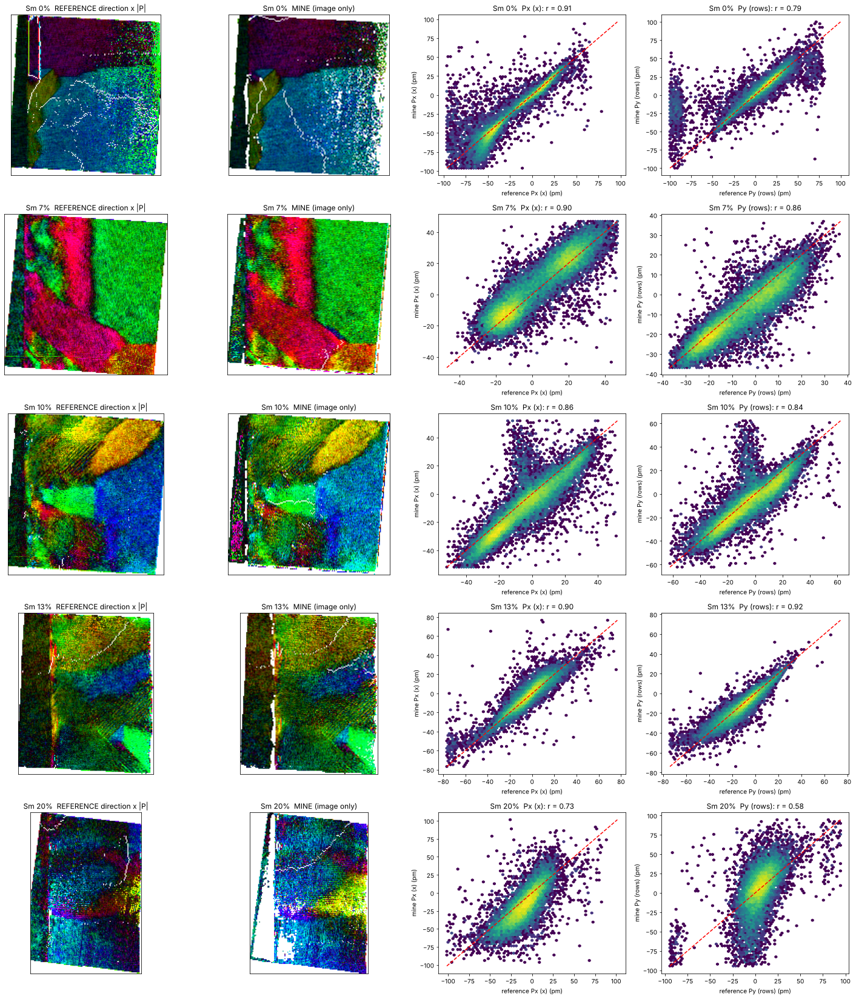

In [ ]:
fig, axs = plt.subplots(len(SM), 4, figsize=(20, 4.6 * len(SM)))
for row, s in zip(axs, SM):
    r, R = RES[s], REF[s]
    ij_ref = sbfo.lattice_index(R['xy'], r['v1'], r['v2'])
    mm = np.percentile(np.hypot(*R['P'].T), 95)
    row[0].imshow(sbfo.direction_rgb(R['P'], ij_ref, mm)); row[0].set_title(f'Sm {s}%  REFERENCE direction x |P|')
    row[1].imshow(sbfo.direction_rgb(r['P'], r['ij'], mm)); row[1].set_title(f'Sm {s}%  MINE (image only)')
    for ax, k, name in ((row[2], 1, 'Px (x)'), (row[3], 0, 'Py (rows)')):
        e, f = r['P'][R['ok'], k] * PX_PM, R['P'][R['j'][R['ok']], k] * PX_PM
        lim = np.percentile(np.abs(f), 99.5)
        ax.hexbin(f, e, gridsize=70, extent=(-lim, lim, -lim, lim), bins='log', cmap='viridis')
        ax.plot([-lim, lim], [-lim, lim], 'r--'); ax.set_xlabel(f'reference {name} (pm)'); ax.set_ylabel(f'mine {name} (pm)')
        ax.set_title(f'Sm {s}%  {name}: r = {np.corrcoef(e, f)[0, 1]:.2f}')
    for ax in row[:2]: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [ ]:
# the same physics numbers, computed on the reference maps (for a fair side-by-side)
cmp = []
for s in SM:
    r, R = RES[s], REF[s]
    t = cKDTree(R['xy'])
    nbr = np.stack([t.query(R['xy'] + sg * v)[1] for v in (r['v1'], r['v2']) for sg in (1, -1)], 1)
    dd = np.stack([t.query(R['xy'] + sg * v)[0] for v in (r['v1'], r['v2']) for sg in (1, -1)], 1); nbr[dd > 0.3 * r['a']] = -1
    w_ref, _ = sbfo.domain_walls(R['P'], nbr)
    cmp.append({'Sm %': s,
                'median |P| pm: mine / ref': f"{PHYS.loc[f'Sm {s}%', 'median |P| (pm)']:.1f} / {np.median(np.hypot(*R['P'].T)) * PX_PM:.1f}",
                'coherence: mine / ref': f"{PHYS.loc[f'Sm {s}%', 'coherence']:.2f} / {np.nanmedian(sbfo.polar_coherence(R['P'], nbr)):.2f}",
                'wall cells %: mine / ref': f"{PHYS.loc[f'Sm {s}%', 'wall cells (%)']:.0f} / {100 * w_ref.mean():.0f}"})
pd.DataFrame(cmp).set_index('Sm %')

,median |P| pm: mine / ref,coherence: mine / ref,wall cells %: mine / ref
Sm %,,,
0,38.5 / 42.6,0.98 / 0.97,12 / 15
7,24.3 / 22.9,0.98 / 0.98,11 / 11
10,26.5 / 23.9,0.96 / 0.97,20 / 18
13,18.3 / 16.7,0.93 / 0.94,18 / 21
20,33.1 / 19.1,0.90 / 0.90,26 / 33


## 7. My answers

_(The numbers quoted here are from my run; the tables above are regenerated every time the notebook runs.)_

### Result in one sentence
From the **raw HAADF image alone**, with no labels and settings chosen by a physics reward, I reconstruct the polarization proxy of every unit cell. It agrees with the reference with **r ≈ 0.8–0.9 per component for 0–13 % Sm**, **97–98 % of strongly polarized cells point within 45° of the reference**, and the magnitude comes out on the right scale (ratio ≈ 1.0–1.1) **without any calibration**.

### Physical assumptions
1. **Z-contrast:** HAADF intensity ∝ ~Z², so bright columns are Bi/Sm, faint columns are Fe and oxygen is invisible.
2. **Polarization proxy = Fe off-centring** relative to the centre of its four Bi/Sm neighbours, with P pointing opposite to the Fe shift (the BFO convention). Applying this formula to the provided coordinates reproduces `Pxy` exactly (method A, r = 1.000), which confirms the definition.
3. **Columns are 2D Gaussians** (probe-limited). A faint Fe peak sitting on the tails of four bright Bi peaks would be biased, so the Bi/Sm columns are modelled and subtracted first.
4. **Polarization is smooth inside domains.** This assumption is only used in the reward (as "noise = disagreement with neighbours") and in the optional denoising for domain segmentation, never to smooth the reported maps.

### Methodology (what makes it intelligent rather than hand-tuned)
- **Fully image-driven:** lattice from the autocorrelation, columns from local maxima, sub-pixel positions from vectorised 2D-Gaussian fits of ~45 000 columns per image in seconds, and blank (NaN) regions masked out.
- **Physics-guided seeding:** Fe is fitted starting from where it *should* be (the cage centre), so no fragile detection of faint peaks is needed.
- **Reward-driven settings:** the score is the signal-to-noise of the P map. It is scale-free, so it can't be gamed by inflating displacements. I validated it on simulations with known truth (Spearman ≈ 0.9; its pick is within 0.6 % of the truly best setting), then applied it to the real data.
- **Unsupervised physics analysis:** polarization variants are found from the direction histogram (no fixed number assumed), domain walls from the local rotation of P, plus coherence and lattice geometry.

### What I learned about the material
- Pure BFO has large, well-ordered domains. Adding Sm reduces |P| and coherence and creates more domain walls (smaller domains), consistent with Sm pushing BFO toward its non-polar / antipolar phase.
- |P| is suppressed by about half at domain walls.
- The data revealed two conventions worth knowing: the coordinates are 1-based, and `Pxy[0]` is the row (y) component, so the starter's arrow plot is transposed.

### Limitations (honest)
- **20 % Sm is the weak point** (r ≈ 0.6–0.7, magnitude overestimated ~1.8×). The image is noisy and the true displacements are small, so measurement noise dominates the magnitude. The reward flags this sample as least reliable *before* looking at the reference. Possible fixes: an elliptical / split-column model for the Bi/Sm sites (antipolar A-site shifts make them non-round) and a noise-bias correction of |P|.
- The 0 % sample's row component (R² ≈ 0.6) suffers from a few strongly distorted regions and local outliers in the reference (|Pxy| up to 28 px).
- Only Fe relative to Bi/Sm is measured. Oxygen octahedra are invisible in HAADF, so the proxy cannot separate polar Fe shifts from octahedral-tilt effects.
- The reward assumes most cells sit inside domains. In a sample made almost entirely of walls it would under-rate good settings.

### Central question: can it be done without precomputed polarization labels?
**Yes.** The polarization proxy is a geometric quantity, so physics gives the model and the image gives the data. Labels are not needed to *learn* the mapping, only to *check* it. The one place where a learned or tuned component is usually required, choosing the analysis settings, can be replaced by a **physics reward** that the image computes for itself. The reference then serves purely as an independent test, and the test passes for 0–13 % Sm.

### With more time
- Elliptical / two-Gaussian A-site model and a joint fit of all columns (better at 20 % Sm).
- Per-cell uncertainty from the Gaussian-fit covariance, shown as an error map.
- Use the reward to also tune the domain-segmentation thresholds (wall angle, non-polar cut-off).
- Link polarization to the local strain and Sm clustering via column-intensity statistics.